In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
batting = pd.read_csv('../baseball_data/NYM_batting.csv')

In [4]:
batting.head()

,Rank,Year,Position,Name,Age,Games,Plate_Appearances,At_Bats,Runs,Hits,...,On_Base_Plus_Slugging_Percentage,On_Base_Plus_Slugging_Percentage_Plus,Total_Bases,Double_Plays_Grounded_Into,Times_Hit_By_Pitch,Sacrifice_Hits,Sacrifice_Flies,Intentional_Bases_on_Balls,Dominant_Hand,Switch_Hitter
0,1,2023,C,Francisco Álvarez,21,123,423,382,51,80,...,0.721,95,167,14,6,0,1,0,Right,No
1,2,2023,1B,Pete Alonso,28,154,658,568,92,123,...,0.821,122,286,17,21,0,4,6,Right,No
2,3,2023,2B,Jeff McNeil,31,156,648,585,75,158,...,0.711,96,221,5,18,3,3,0,Left,No
3,4,2023,SS,Francisco Lindor,29,160,687,602,108,153,...,0.806,120,283,8,12,0,7,1,Right,Yes
4,5,2023,3B,Brett Baty,23,108,389,353,41,75,...,0.598,65,114,8,2,1,1,0,Left,No


In [5]:
batting.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2728 entries, 0 to 2727
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Rank                                   2728 non-null   int64  
 1   Year                                   2728 non-null   int64  
 2   Position                               2709 non-null   object 
 3   Name                                   2728 non-null   object 
 4   Age                                    2728 non-null   int64  
 5   Games                                  2728 non-null   int64  
 6   Plate_Appearances                      2728 non-null   int64  
 7   At_Bats                                2728 non-null   int64  
 8   Runs                                   2728 non-null   int64  
 9   Hits                                   2728 non-null   int64  
 10  Doubles                                2728 non-null   int64  
 11  Trip

First, about the batting dataset. There are three categories of variables. First, the player demographics, which indicates the identifiers, demographic, defensive role, and physical traits of the player. Second, the opportunity and volume metrics, including how often the players play in the games, which implies how well the coach trusts the player, but this does not necessarily the player has a good performance. Third, offensive output and events, including different ways of scoring or different ways how players miss a chance of scoring intentionally for tactical playing. These values are raw counts without without standardizations. Fourth, rate and efficiency, which includes traditional metrics that evaluates how often the player gets a hit, how often a player avoids getting out (this is important for teamwork), metric that gives extra weight to extra-base hits that earns more points at a time, and composite metric combining the ability to get a base and the hits for power. 

              Rank         Year          Age        Games  Plate_Appearances  \
count  2728.000000  2728.000000  2728.000000  2728.000000        2728.000000   
mean     23.054985  1994.592009    28.060484    48.831012         136.707478   
std      13.676628    18.233108     4.317141    45.156003         187.243661   
min       1.000000  1962.000000    17.000000     0.000000           0.000000   
25%      11.750000  1979.000000    25.000000    12.000000           3.000000   
50%      22.500000  1996.000000    27.000000    33.000000          44.000000   
75%      34.000000  2010.000000    31.000000    74.000000         205.000000   
max      64.000000  2023.000000    48.000000   162.000000         765.000000   

           At_Bats         Runs         Hits      Doubles      Triples  ...  \
count  2728.000000  2728.000000  2728.000000  2728.000000  2728.000000  ...   
mean    121.663856    14.793988    30.409091     5.414589     0.656525  ...   
std     166.672170    23.514480    45.5505

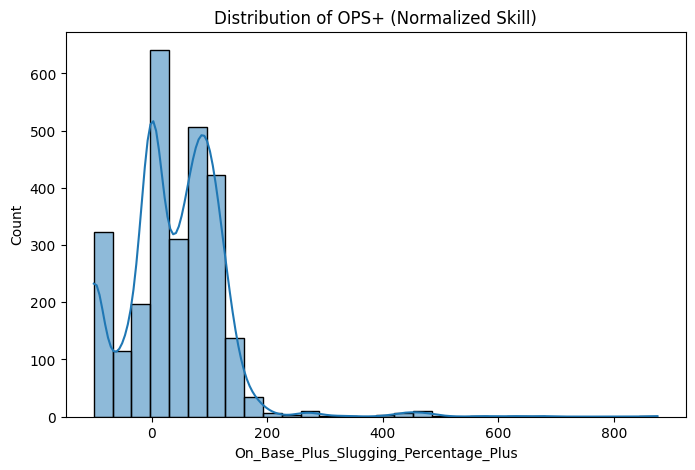

In [6]:
# Basic summary for numerical columns
print(batting.describe())

# Check distribution of OPS+ (league-normalized skill metric)
plt.figure(figsize=(8, 5))
sns.histplot(batting['On_Base_Plus_Slugging_Percentage_Plus'], kde=True, bins=30)
plt.title('Distribution of OPS+ (Normalized Skill)')
plt.show()

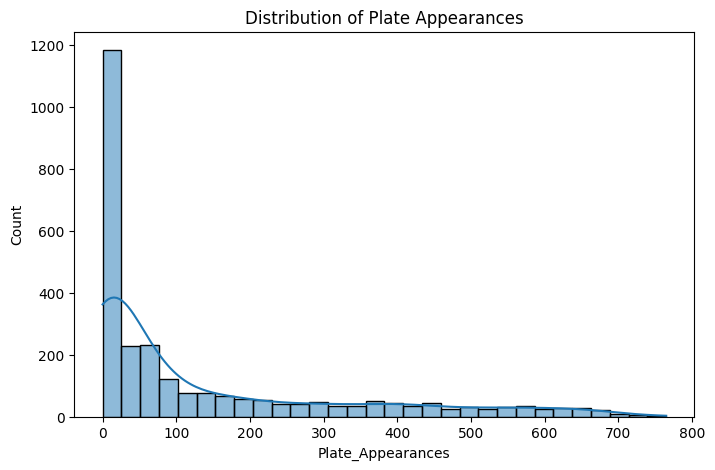

In [7]:
# Check distribution of Plate Appearances (PA) to see the skewness
plt.figure(figsize=(8, 5))
sns.histplot(batting['Plate_Appearances'], kde=True, bins=30)
plt.title('Distribution of Plate Appearances')
plt.show()

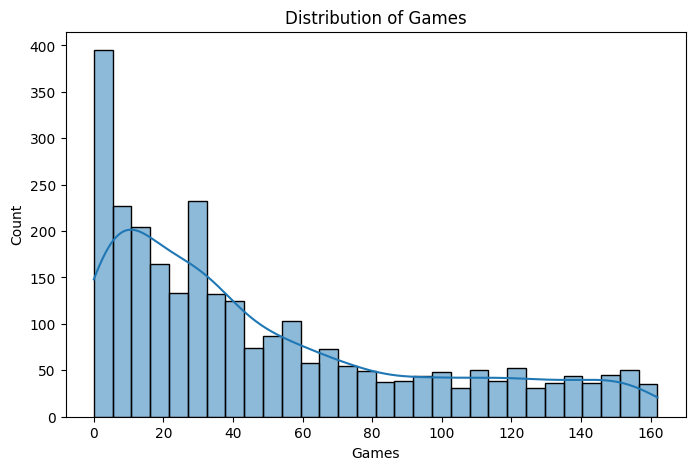

In [8]:
# Check distribution of Games to see the skewness
plt.figure(figsize=(8, 5))
sns.histplot(batting['Games'], kde=True, bins=30)
plt.title('Distribution of Games')
plt.show()

The distribution of Plate_Appearances and Games both show a heavy right skewness, which indicates that there are many players who play in a few games, but less players who play in many games. This means playing opportunities are really limited.

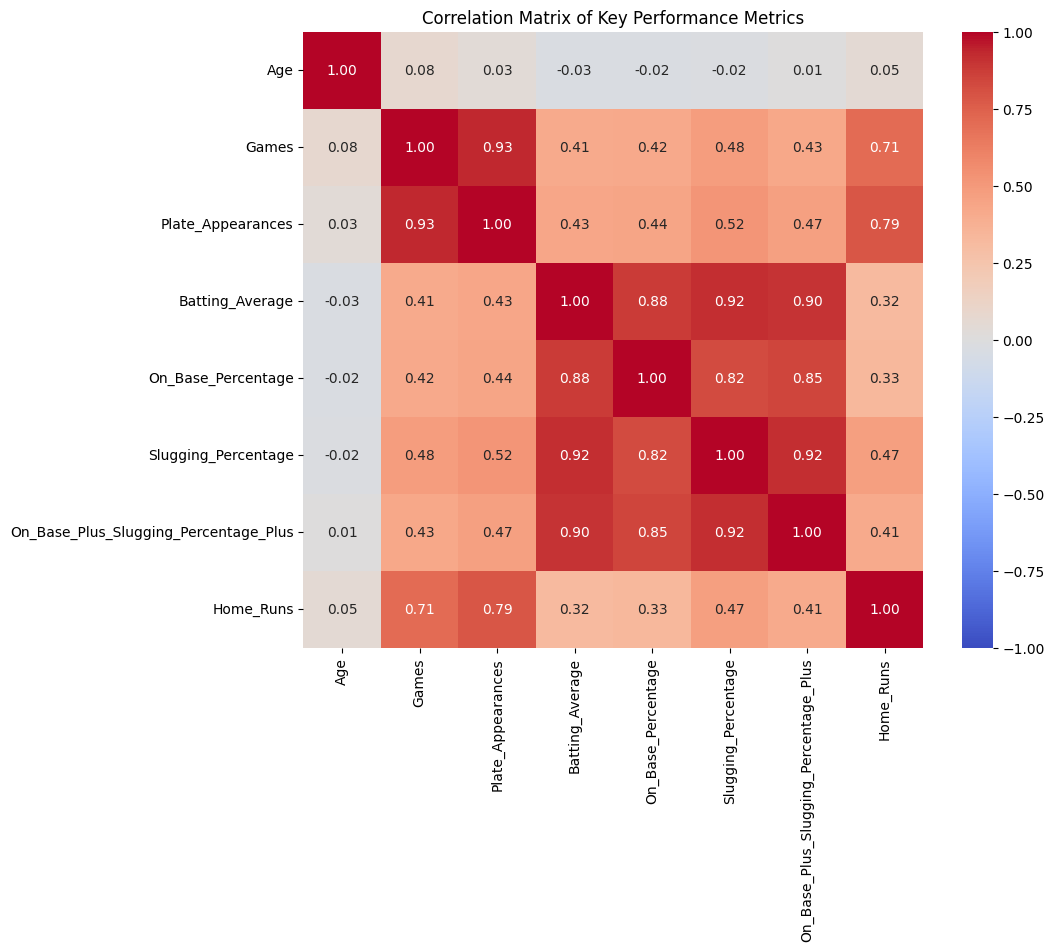

In [9]:
# Select key performance columns with standardized metrics for correlation analysis
performance_g1 = ['Age', 'Games', 'Plate_Appearances', 'Batting_Average', 
            'On_Base_Percentage', 'Slugging_Percentage', 'On_Base_Plus_Slugging_Percentage_Plus', 'Home_Runs']

# Calculate correlation matrix
corr_matrix = batting[performance_g1].corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Key Performance Metrics')
plt.show()

The high correlations in the matrix and the heatmap can be categorized into two different group. 

For the first group, the high correlation does not indicate anything because the variables are calculated from each other. For example, Slugging_Percentage is calculated by (Total Bases)/(At Bats), and therefore has a high (0.92) correlation with Batting_average. The same thing happens with On_Base_Percentage, which is calculated from (Hits + Base_On_Balls + Times_Hit_By_Pitch)/(Plate_Appearance), and therefore it has a high (0.88) correlation with Batting_average. Since Batting_Percentage serves as a confounding variable, it is no surprise that On_Base_Percentage has a high correlation with Slugging_Percentage. 

For the second group, the high correlation between two variables can indicate players are trusted to play in more games if they have good performance. See the 0.71 correlation between Home_Runs and Games, which means players who have more home runs will likely to get chances to play in more games. Does this mean players with greater hitting power get more chance to play? By looking at the 0.48 correlation between Slugging_Percentage and Games, we see a lower correlation, which means this is not the case. Does a combination of ability to get a base and hitting power gives a player greater chance to play in game? Not necessarily, because the correlation between On_Base_Plus_Slugging_Percentage_Plus is 0.43. This raise a question: How come the chances of the players to play in the games more correlated with Home Runs but not with overall performance? Which is a sufficient way of evaluating an athletes' ability?

In counting-stat analysis, metrics like Home Runs correlate strongly with overall Plate Appearances. This exposes two critical flaws in player evaluation. First, metrics intended to capture overall athletic ability often reflect sheer volume of opportunity instead. Second, decisional models (both human coaches and algorithms) tend to over-index on high-impact, flashy events (like Home Runs) rather than consistent, baseline productivity, skewing how true "value" is operationalized in the dataset.

The next thing to look at is the distribution of 

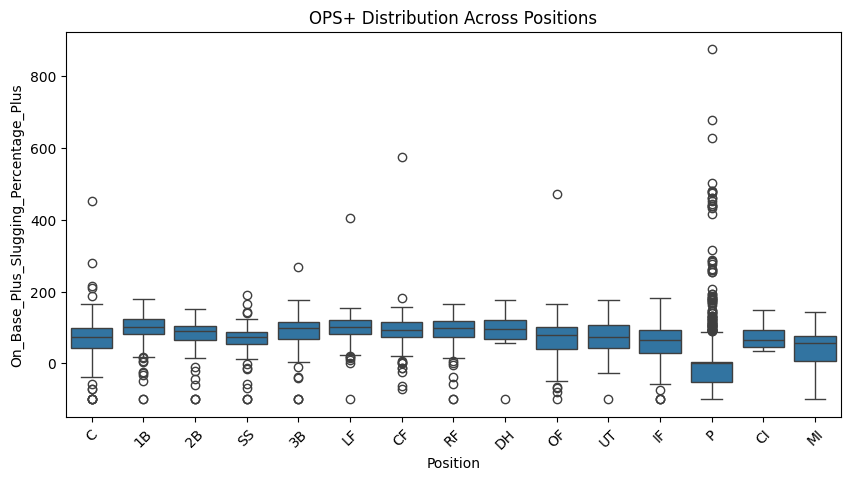

Dominant_Hand
Right    1938
Left      790
Name: count, dtype: int64


In [10]:
# Compare average OPS+ across different positions
plt.figure(figsize=(10, 5))
sns.boxplot(x='Position', y='On_Base_Plus_Slugging_Percentage_Plus', data=batting)
plt.title('OPS+ Distribution Across Positions')
plt.xticks(rotation=45)
plt.show()

# Check counts of dominant hand
print(batting['Dominant_Hand'].value_counts())

In [11]:
player_seasons = batting['Name'].value_counts()
player_seasons.head(10)

Name
Ed Kranepool     18
David Wright     14
John Franco      14
Bud Harrelson    13
Jerry Grote      12
Jerry Koosman    12
Craig Swan       12
Tom Seaver       12
Cleon Jones      12
Ron Hodges       12
Name: count, dtype: int64

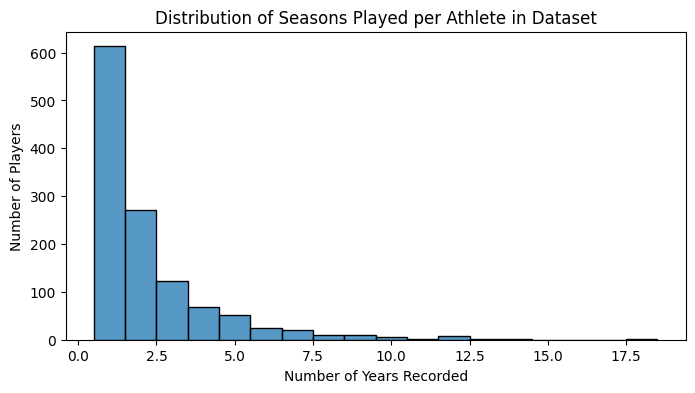

In [12]:
# Plot the distribution of career lengths within your dataset timeframe
plt.figure(figsize=(8, 4))
sns.histplot(player_seasons, discrete=True)
plt.title('Distribution of Seasons Played per Athlete in Dataset')
plt.xlabel('Number of Years Recorded')
plt.ylabel('Number of Players')
plt.show()

Standardized metrics like On-Base Plus Slugging Plus ($\text{OPS+}$) are designed to isolate player quality, but they become highly volatile when applied to small sample sizes. For specialized roles like Pitchers, a low denominator in opportunities (e.g., very few Plate Appearances) means a single successful outcome creates a artificially inflated metric. Naïve algorithms that ingest these rate metrics without filtering for minimum participation thresholds risk evaluating fluke performances as genuine elite ability.

Evaluating players solely on rate metrics like $\text{OPS+}$ does not equalize opportunities or create a fairer system for bench players. Because total opportunities (Plate Appearances) are heavily right-skewed, players with high initial playing time generate reliable, high-volume data, while underutilized players remain trapped in low-sample uncertainty. Rather than acting as a neutral equalizer, reliance on these metrics often reinforces existing roster hierarchies through a self-fulfilling feedback loop.